# Retail Sales | Executive Dashboard 🌿
**DataSense Python Capstone · Forest Green & Cream · 1920 × 1080**

This **separate dashboard notebook** reads the seven cleaned CSVs generated by the validated analysis notebook. It does **not** modify the analysis notebook. Run from the project's `notebooks/` directory, with cleaned files under `../data/cleaned/`.

**Metric policy:** Completed orders only; discounted merchandise revenue; shipping and refunds excluded. Customer “New” means first **observed** order, not verified first-ever purchase.

## 1. Load cleaned data and reconstruct the validated metrics

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

ROOT = Path.cwd().resolve()
if ROOT.name.lower() == 'notebooks':
    ROOT = ROOT.parent
CLEANED = ROOT / 'data' / 'cleaned'
OUT = ROOT / 'outputs' / 'figures'
OUT.mkdir(parents=True, exist_ok=True)

required = ['customers', 'products', 'orders', 'order_items']
missing = [name for name in required if not (CLEANED / f'{name}_cleaned.csv').exists()]
if missing:
    raise FileNotFoundError(f'Missing cleaned CSV files in {CLEANED}: {missing}. Run the validated analysis notebook export first.')
customers, products, orders, order_items = [pd.read_csv(CLEANED / f'{name}_cleaned.csv') for name in required]
orders['order_datetime'] = pd.to_datetime(orders['order_datetime'], errors='coerce')
assert orders['order_datetime'].notna().all(), 'Some cleaned order dates could not be parsed.'

sales_fact = (order_items.merge(orders, on='order_id', how='left', validate='many_to_one')
              .merge(products, on='product_id', how='left', validate='many_to_one', suffixes=('', '_product'))
              .merge(customers, on='customer_id', how='left', validate='many_to_one', suffixes=('', '_customer')))
for col in ['quantity', 'unit_price_at_purchase', 'discount_pct_for_analysis']:
    sales_fact[col] = pd.to_numeric(sales_fact[col], errors='coerce')
assert sales_fact['discount_pct_for_analysis'].notna().all(), 'Missing analysis discount rate.'
valid = sales_fact['quantity'].gt(0) & sales_fact['unit_price_at_purchase'].notna()
sales_fact['revenue_eligible'] = sales_fact['order_status'].eq('Completed') & valid
sales_fact['sales_revenue'] = (sales_fact['quantity'] * sales_fact['unit_price_at_purchase'] *
                               (1 - sales_fact['discount_pct_for_analysis'])).where(sales_fact['revenue_eligible'], 0)
revenue = sales_fact['sales_revenue'].sum()
completed = orders.loc[orders['order_status'].eq('Completed'), 'order_id'].nunique()
aov = revenue / completed
units = sales_fact.loc[sales_fact['revenue_eligible'], 'quantity'].sum()
assert len(orders) == 15000 and completed == 9850
assert abs(revenue - 4461673.07) < .01, f'Revenue mismatch: {revenue:,.2f}'
assert units == 52011
print(f'PASS | Revenue PHP {revenue:,.2f} | Completed orders {completed:,} | AOV PHP {aov:,.2f} | Units {units:,}')

PASS | Revenue PHP 4,461,673.07 | Completed orders 9,850 | AOV PHP 452.96 | Units 52,011


## 2. Prepare dashboard series

In [2]:
monthly = (sales_fact.assign(month=sales_fact['order_datetime'].dt.to_period('M'))
           .groupby('month')['sales_revenue'].sum().sort_index())
category = (sales_fact.assign(category_label=sales_fact['category'].fillna('Unknown Category'))
            .groupby('category_label')['sales_revenue'].sum().sort_values(ascending=False))
region_col = 'region_name' if 'region_name' in sales_fact.columns else 'region'
regional = (sales_fact.assign(region_label=sales_fact[region_col].fillna('Unknown Region'))
            .groupby('region_label')['sales_revenue'].sum().sort_values(ascending=False))
customer_orders = (orders[['order_id','customer_id','order_datetime','order_status']]
                   .drop_duplicates('order_id').sort_values(['customer_id','order_datetime','order_id']).copy())
customer_orders['type'] = np.where(customer_orders.groupby('customer_id').cumcount().eq(0), 'New', 'Repeat')
completed_orders = customer_orders.loc[customer_orders['order_status'].eq('Completed')]
customer_counts = completed_orders.groupby('type')['order_id'].nunique().reindex(['New','Repeat'], fill_value=0)
assert customer_counts.sum() == completed
assert abs(category.sum() - revenue) < .01 and abs(regional.sum() - revenue) < .01
print('PASS | Monthly, category, region and customer-type metrics prepared.')
print('Completed-order counts by first/subsequent observed order:', customer_counts.to_dict())

PASS | Monthly, category, region and customer-type metrics prepared.
Completed-order counts by first/subsequent observed order: {'New': 3124, 'Repeat': 6726}


## 3. Render and export the 1920 × 1080 dashboard

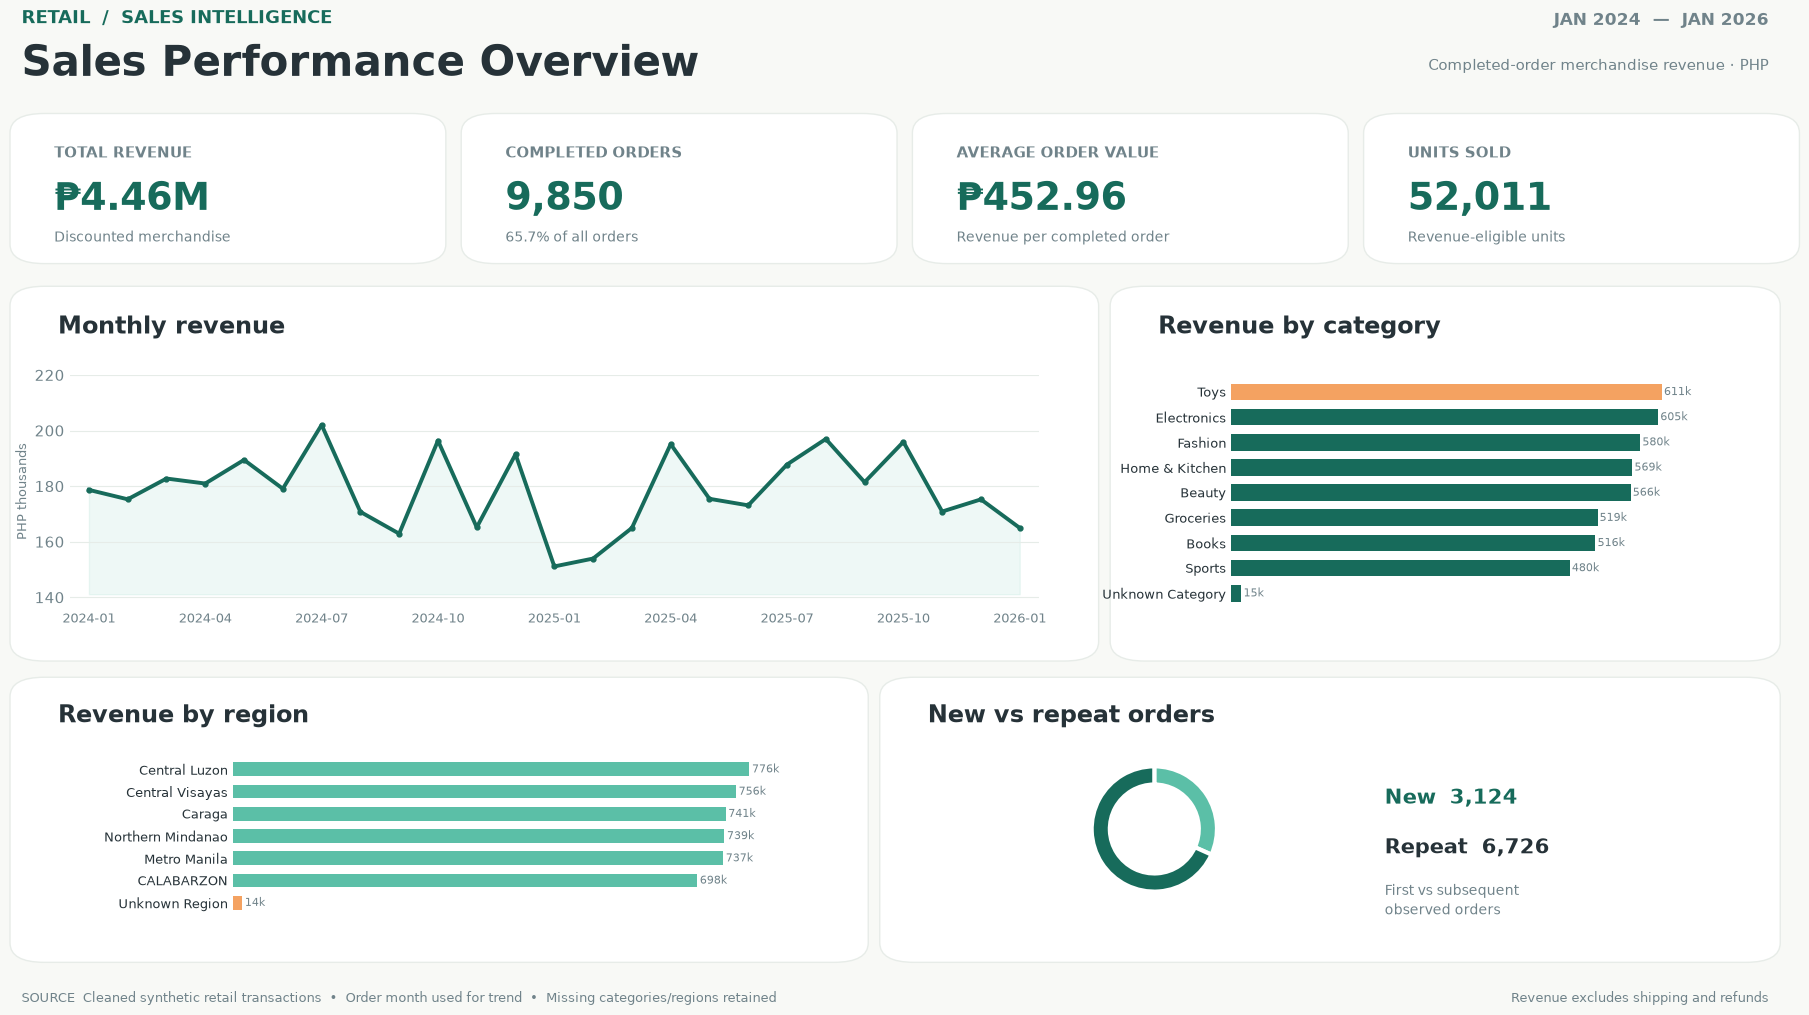

PASS | Exported: C:\PythonProjects\Retail_Sales_Capstone\outputs\figures\retail_executive_dashboard_1920x1080.png
PASS | Resolution: 1920 × 1080


In [4]:
# Canvas uses 100 dpi × 19.2 × 10.8 inches = exactly 1920 × 1080 pixels.
BG='#F8F9F6'; WHITE='#FFFFFF'; GREEN='#176B5B'; TEAL='#5BBFA7'
ORANGE='#F4A261'; INK='#263238'; MUTED='#70838A'; GRID='#E6ECE8'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11})
fig=plt.figure(figsize=(19.2,10.8),dpi=100,facecolor=BG)

def card(x,y,w,h, radius=.018):
    patch=FancyBboxPatch((x,y),w,h,boxstyle=f'round,pad=0.006,rounding_size={radius}',
                         transform=fig.transFigure,facecolor=WHITE,edgecolor='#E7ECE8',linewidth=1,zorder=0)
    fig.patches.append(patch)

def label(x,y,t,size=12,color=INK,weight='normal',ha='left'):
    fig.text(x,y,t,fontsize=size,color=color,fontweight=weight,ha=ha,va='center',zorder=10)

label(.045,.948,'RETAIL  /  SALES INTELLIGENCE',13,GREEN,'bold')
label(.045,.905,'Sales Performance Overview',30,INK,'bold')
label(.955,.946,'JAN 2024  —  JAN 2026',12,MUTED,'bold','right')
label(.955,.904,'Completed-order merchandise revenue · PHP',11,MUTED,ha='right')

kpis=[('TOTAL REVENUE',f'₱{revenue/1e6:,.2f}M','Discounted merchandise'),
      ('COMPLETED ORDERS',f'{completed:,}','65.7% of all orders'),
      ('AVERAGE ORDER VALUE',f'₱{aov:,.2f}','Revenue per completed order'),
      ('UNITS SOLD',f'{int(units):,}','Revenue-eligible units')]
for j,(title,value,sub) in enumerate(kpis):
    x=.045+j*.235
    card(x,.727,.215,.127)
    label(x+.017,.823,title,11,MUTED,'bold')
    label(x+.017,.780,value,27,GREEN,'bold')
    label(x+.017,.745,sub,10,MUTED)

# Main chart panels
card(.045,.359,.555,.335); card(.618,.359,.337,.335)
card(.045,.080,.435,.252); card(.498,.080,.457,.252)
label(.064,.662,'Monthly revenue',17,INK,'bold')
label(.637,.662,'Revenue by category',17,INK,'bold')
label(.064,.302,'Revenue by region',17,INK,'bold')
label(.517,.302,'New vs repeat orders',17,INK,'bold')

ax=fig.add_axes([.070,.402,.505,.216],zorder=2)
x=np.arange(len(monthly)); vals=monthly.values/1000
ax.plot(x,vals,color=GREEN,lw=2.8,marker='o',ms=3.5)
ax.fill_between(x,vals,vals.min()-10,color=TEAL,alpha=.10)
ax.set_xlim(-.5,len(x)-.5)
ax.set_ylim(max(0,vals.min()-15),vals.max()+18)
ax.set_xticks(np.arange(0,len(x),3),[str(monthly.index[i]) for i in range(0,len(x),3)],fontsize=9)
ax.set_ylabel('PHP thousands',fontsize=9,color=MUTED)
ax.grid(axis='y',color=GRID)
ax.spines[:].set_visible(False)
ax.tick_params(length=0,labelcolor=MUTED)

ax=fig.add_axes([.675,.398,.258,.222],zorder=2)
cat=category.sort_values(ascending=True)
colors=[ORANGE if v==cat.max() else GREEN for v in cat.values]
ax.barh(range(len(cat)),cat.values/1000,color=colors,height=.66)
ax.set_yticks(range(len(cat)),cat.index,fontsize=9)
ax.set_xlim(0,cat.max()/1000*1.15)
ax.set_xticks([])
ax.spines[:].set_visible(False)
ax.tick_params(length=0,labelcolor=INK)
for i,v in enumerate(cat.values):ax.text(v/1000+3,i,f'{v/1000:.0f}k',va='center',fontsize=8,color=MUTED)

ax=fig.add_axes([.155,.116,.296,.150],zorder=2)
reg=regional.sort_values(ascending=True)
ax.barh(range(len(reg)),reg.values/1000,color=[TEAL if 'Unknown' not in str(k) else ORANGE for k in reg.index],height=.62)
ax.set_yticks(range(len(reg)),reg.index,fontsize=9)
ax.set_xticks([]);ax.set_xlim(0,reg.max()/1000*1.10)
ax.spines[:].set_visible(False);ax.tick_params(length=0,labelcolor=INK)
for i,v in enumerate(reg.values):ax.text(v/1000+4,i,f'{v/1000:.0f}k',va='center',fontsize=8,color=MUTED)

ax=fig.add_axes([.545,.125,.180,.145],zorder=2)
ax.pie(customer_counts.values,colors=[TEAL,GREEN],startangle=90,counterclock=False,
       wedgeprops={'width':.29,'edgecolor':WHITE,'linewidth':3})
label(.755,.226,f'New  {customer_counts["New"]:,}',15,GREEN,'bold')
label(.755,.180,f'Repeat  {customer_counts["Repeat"]:,}',15,INK,'bold')
label(.755,.140,'First vs subsequent',10,MUTED)
label(.755,.122,'observed orders',10,MUTED)

label(.045,.041,'SOURCE  Cleaned synthetic retail transactions  •  Order month used for trend  •  Missing categories/regions retained',9,MUTED)
label(.955,.041,'Revenue excludes shipping and refunds',9,MUTED,ha='right')
output=OUT/'retail_executive_dashboard_1920x1080.png'
fig.savefig(output,dpi=100,facecolor=BG)
plt.show()
from PIL import Image
assert Image.open(output).size == (1920,1080)
print('PASS | Exported:',output)
print('PASS | Resolution: 1920 × 1080')

## Interpretation and usage notes
- The dashboard is an **executive summary**, not a replacement for the five required detailed chart PNGs already exported by the analysis notebook.
- **New / Repeat** refers to **completed orders** classified using each customer's first observed order **across all statuses**. It does not measure customer acquisition or unique customer retention.
- Unknown categories and regions remain included to reconcile with total revenue.
- **No source data is modified.** If any validation fails, resolve the discrepancy in the cleaned source exports before publishing.
- Save the exported PNG under `outputs/figures/` and use it in the PDF report.